pybullet build time: Jan 29 2025 23:16:28


navigation policy: models/navigation_policy.zip | walking policy: models/walking_policy.zip
walking env | observation (50,) | action (12,) | policy step 0.020 s
omni command range (min, max):
              min  max
vx (m/s)    -0.6  2.0
vy (m/s)    -0.5  0.5
yaw (rad/s) -1.0  1.0
navigation command range:


,min,max
vx (m/s),-0.1,1.2
vy (m/s),-0.2,0.2
yaw (rad/s),-1.0,1.0


navigation reward (sum of the terms):


,value,when
term,,
progress,+5 per metre closer to the goal,every step
time,-0.02,every step
unseen,-0.02 while the goal is not in view,every step
smooth,-0.02 * |a - a_prev|^2,every step
near,"0 beyond 0.35 m from an obstacle, -1 at contac...",every step
reached,+10,end: success
crash,-10 (Q2: -30),end: obstacle contact
fell,-5,end: robot fell
lost,-5,end: left the arena


goal: [3.  2.8] | obstacles on the standard map: 13 | depth range: (0.28, 20.0) m


,x0 (m),y0 (m),heading (deg),straight line to goal (m)
test,,,,
1,-3.2,-3.2,45,8.63
2,-3.3,-1.0,0,7.36
3,-3.3,1.2,0,6.50
4,-1.5,-3.3,90,7.58
5,0.8,-3.3,90,6.48


navigation env | observation (28,) | action (3,) | step 0.1 s | max 600 steps


test  start          heading  result     time(s)  path(m)  straight(m)  min clearance(m)
   1  (-3.2, -3.2)     45°   success       13.0    10.65         8.63              0.18
   2  (-3.3, -1.0)      0°   success        6.7     7.47         7.36              0.12
   3  (-3.3, +1.2)      0°   collision      1.7     1.18         6.50              0.00
   4  (-1.5, -3.3)     90°   success       37.2    11.87         7.58              0.10
   5  (+0.8, -3.3)     90°   success        6.2     6.65         6.48              0.23
reached the goal: 4 / 5   (nav models/navigation_policy.zip, walker models/walking_policy.zip)


q2_trajectories.png


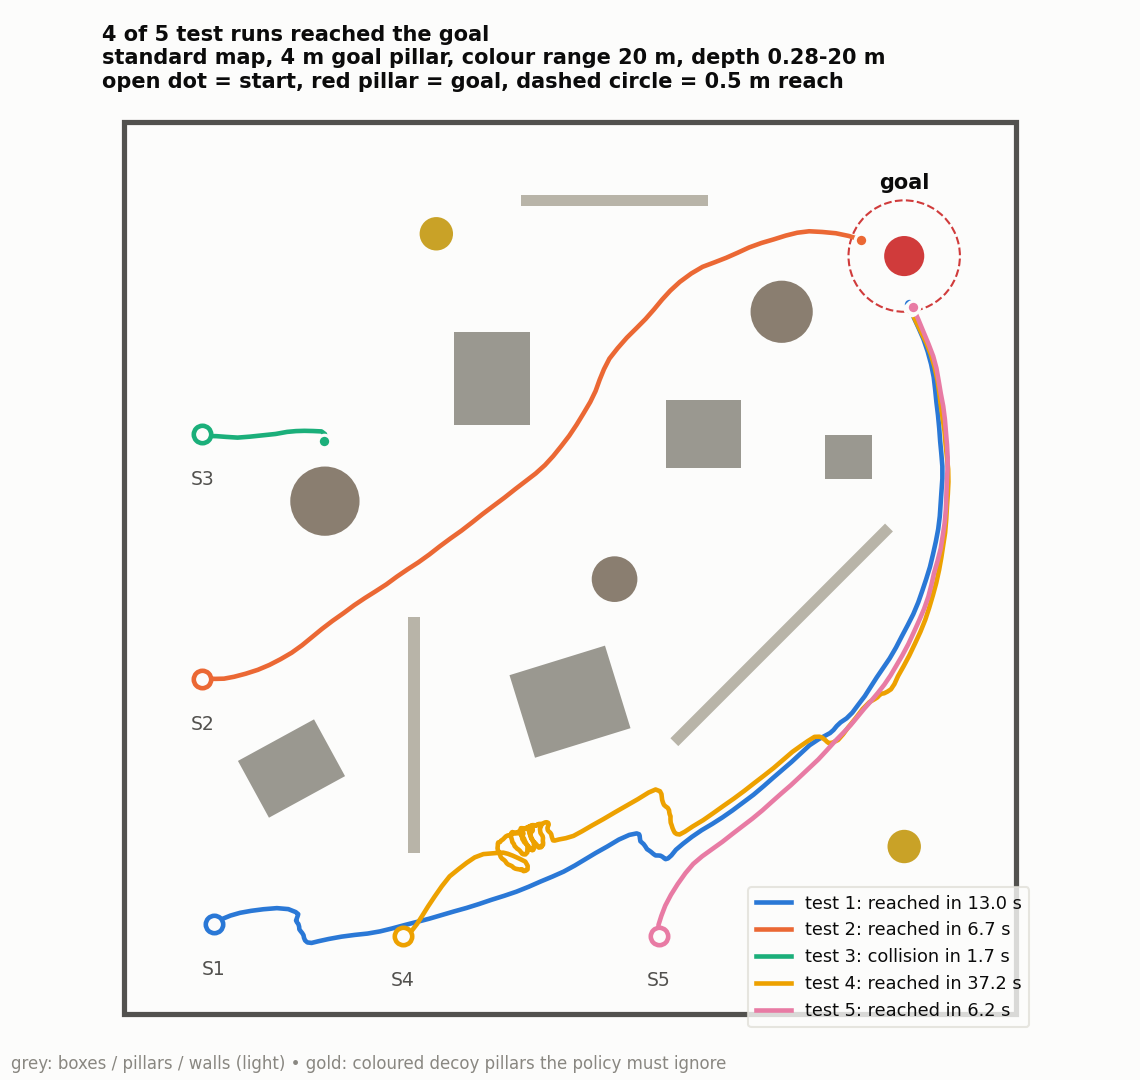

q2_distance.png


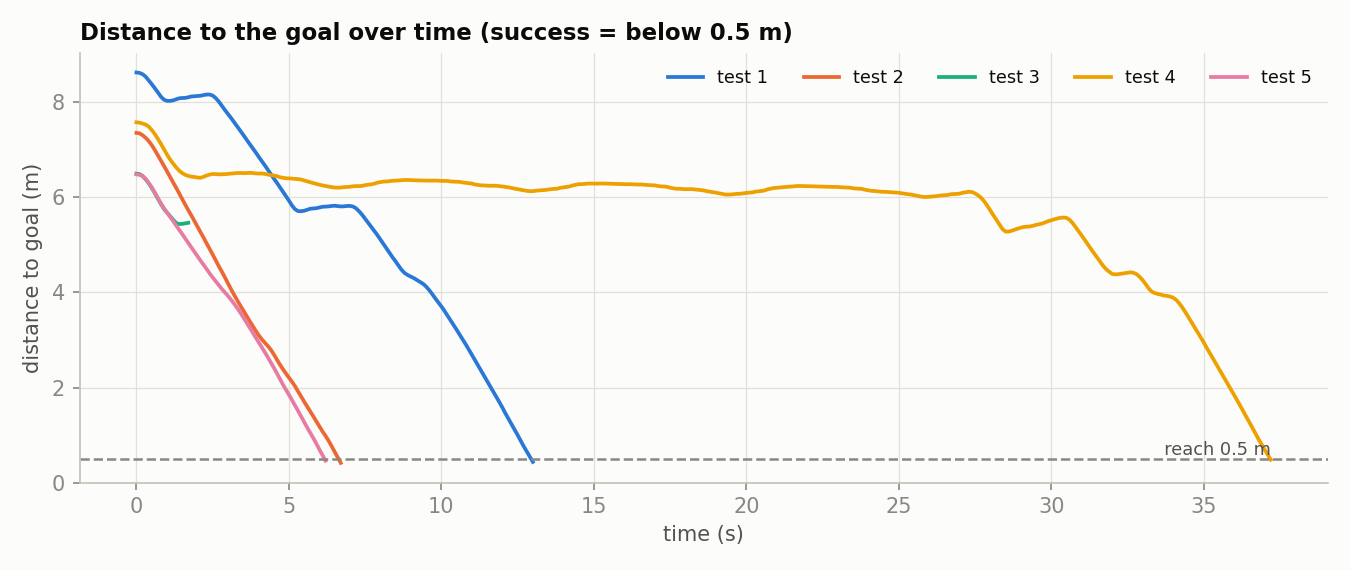

q2_clearance.png


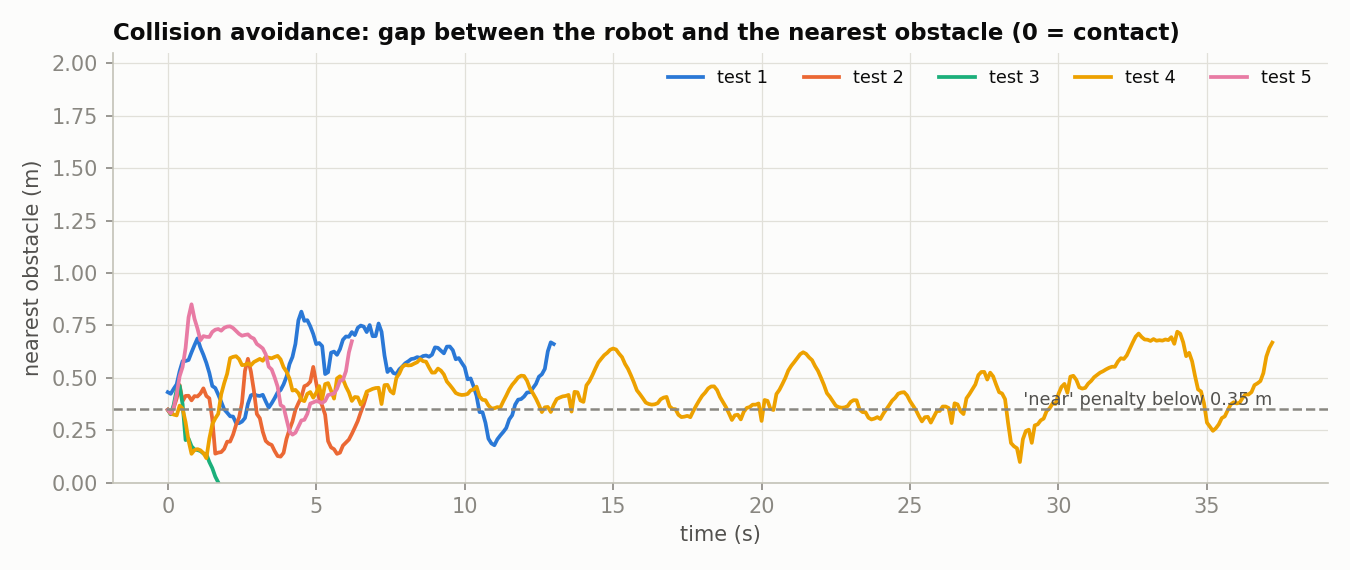

q2_commands.png


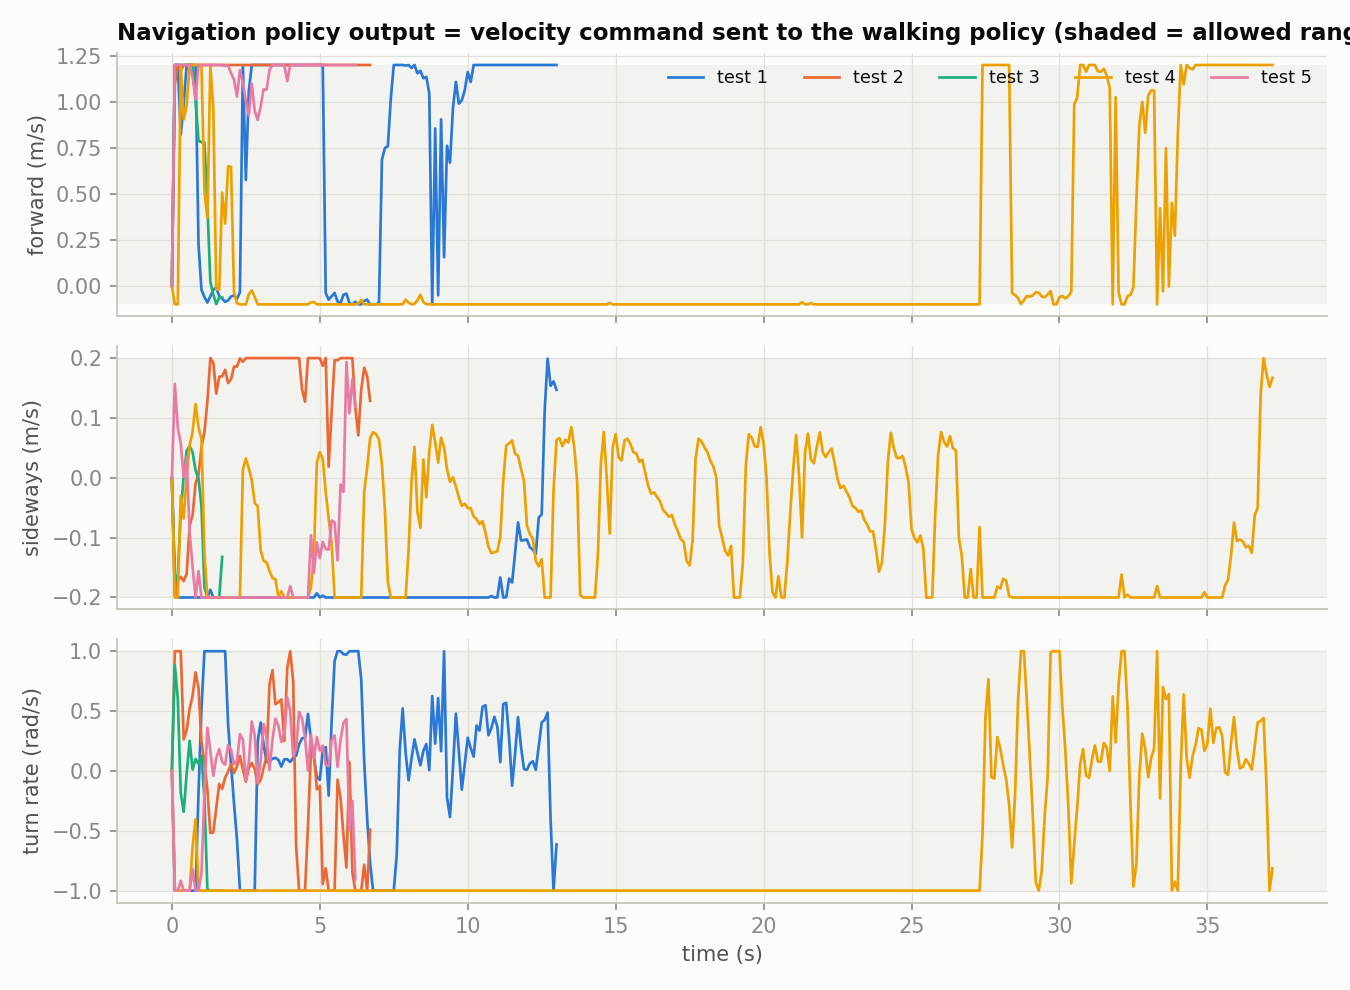

q2_observation.png


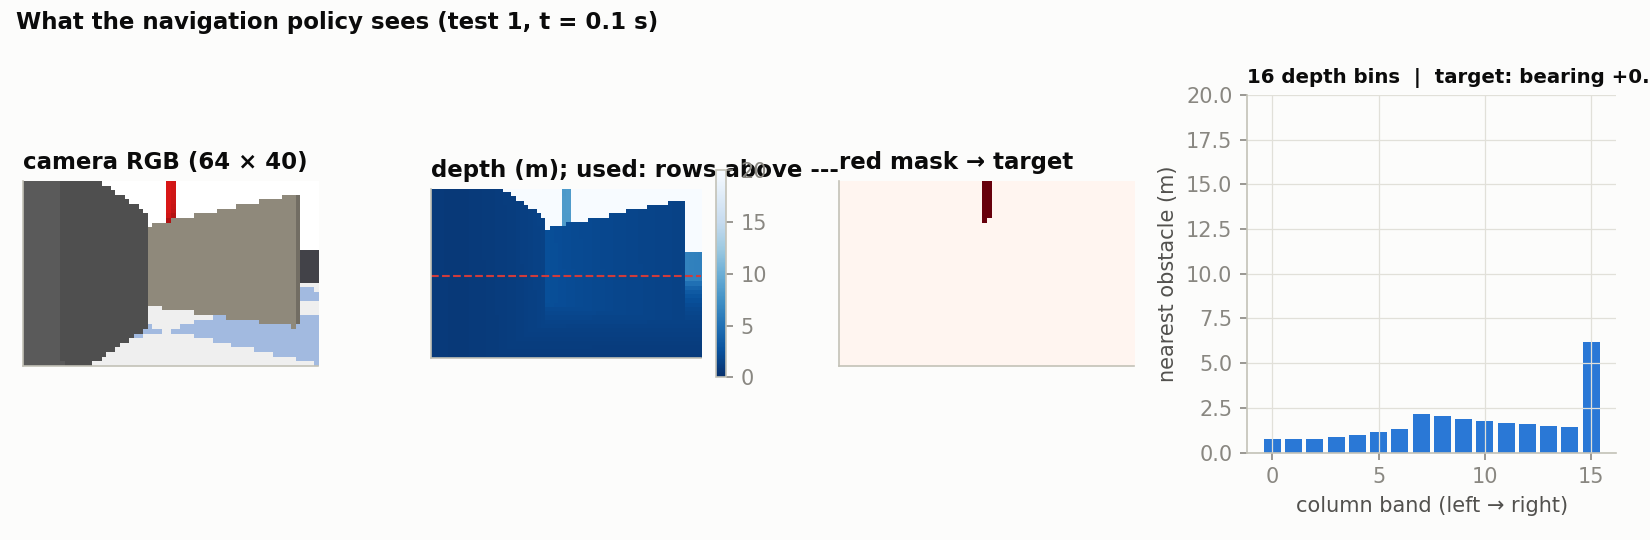

q2_training.png


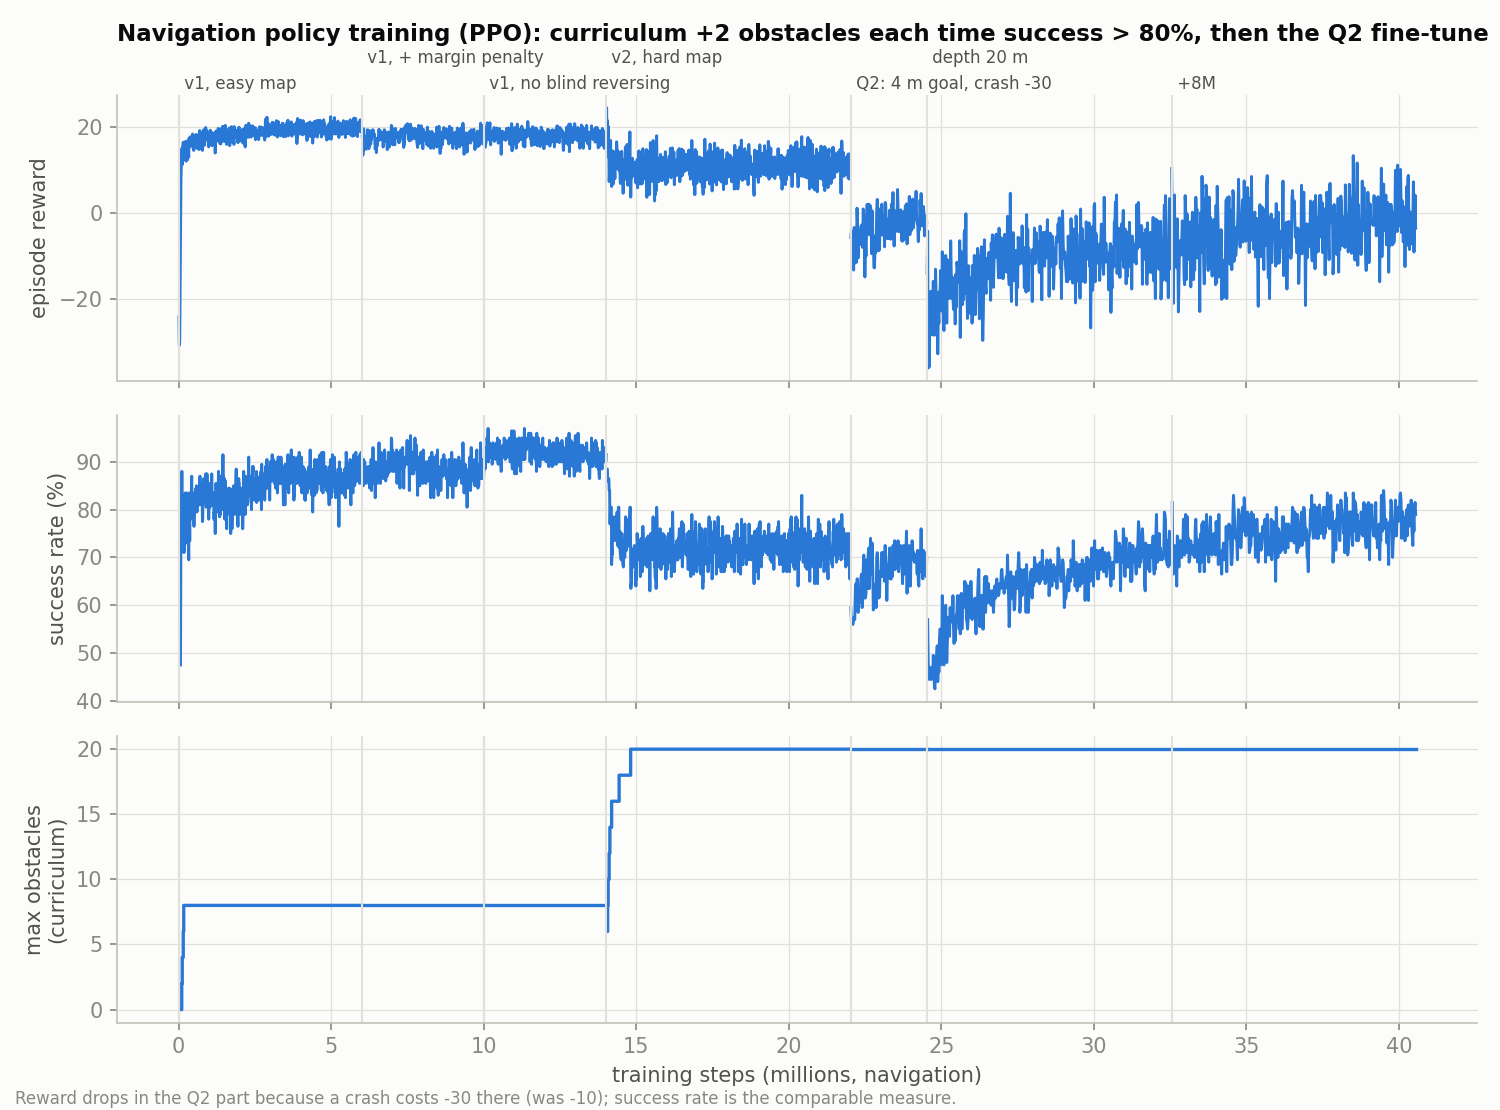

['q2_all_tests.gif', 'q2_test1.gif', 'q2_test2.gif', 'q2_test3.gif', 'q2_test4.gif', 'q2_test5.gif']


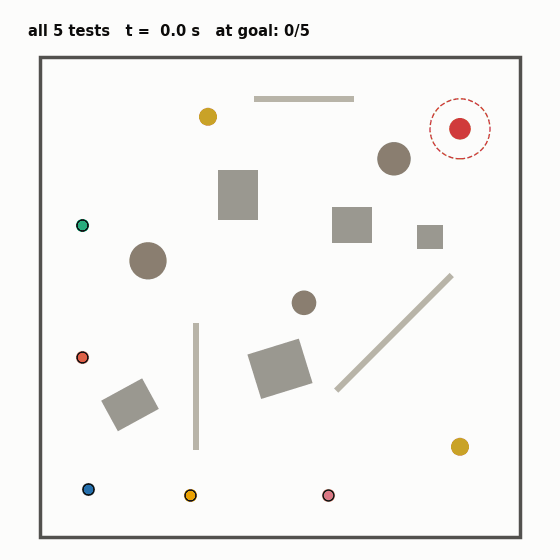

In [1]:
# Q2 — Lite3 quadruped: camera-based navigation with collision avoidance (PPO, PyBullet)
# Assignment option 2: own simulator (PyBullet) and robot (Lite3). Every section starts with a short explanation
# followed by its code. The code itself lives in the .py files of this folder; this notebook imports it, explains
# it, runs the 5 tests and shows the results, plots and GIFs in order.
#
# Running: RUN_TESTS = True runs the 5 tests again with the saved policies (about 1 min on 5 processes) and
# rewrites results/, plots/final/ and gifs/final/. RUN_TESTS = False only loads results/final_runs.pkl.
# Training is NOT run here (hours); the commands are given in §6.

# ====================================================================================================
# §1. Setup and configuration
# ====================================================================================================
# Task (assignment, option 2): pick a simulator and a robot, learn to navigate autonomously with collision
#   avoidance to a predefined goal, save the model, test it 5 times and compare the trajectories.
# Choice: PyBullet + the DEEP Robotics Lite3 quadruped (URDF in Lite3/), Stable-Baselines3 PPO.
# Two policies, trained one after the other:
#   1. walking policy    (walking_env.py)      velocity command -> 12 joint targets, 50 Hz
#   2. navigation policy (navigation_env.py,  camera image -> velocity command,     10 Hz
#                         q2_navigation_env.py)  the frozen walking policy executes the command

import os
import sys

HERE = os.path.abspath("")                       # the notebook runs from q2/
for sub in ("", "plots", "gifs"):
    sys.path.insert(0, os.path.join(HERE, sub))

import pickle
import numpy as np
import pandas as pd
from IPython.display import Image, display

import navigation_env as nav
import walking_env as walk
from q2_navigation_env import Q2NavigationEnv, MAPS, GOAL, TESTS, DEPTH_RANGE
from run_tests import config_from_preset, run_all, save_results
from make_plots import make_all
from make_gifs import all_tests_gif

RUN_TESTS = True                                  # False -> load the saved runs (results/final_runs.pkl)
CFG = config_from_preset("final")                 # final Q2 setup: 4 m goal pillar, 20 m camera range
print("navigation policy:", CFG["nav"], "| walking policy:", CFG["walker"])


# ====================================================================================================
# §2. Low level: the walking environment (walking_env.Lite3Env)
# ====================================================================================================
# Robot: Lite3, 12 actuated joints (HipX, HipY, Knee per leg), loaded from Lite3/urdf/Lite3.urdf.
# Simulation: PyBullet DIRECT (headless), physics step 0.005 s, policy step 0.02 s (50 Hz, decimation 4).
# Action (12): joint-angle offsets from DEFAULT_POSE, scaled by 0.5 rad; a PD controller (kp 45, kd 1) makes
#   the torques.
# Observation (50): body velocities, gravity direction, joint angles and speeds, previous action, the velocity
#   command (vx, vy, yaw rate) and a gait clock (trot: FL+HR and FR+HL step together, 0.3-0.4 s per cycle).
# Reward: mostly tracking of the commanded velocity (exp(-error) terms) plus gait, foot clearance, body height,
#   level body; penalties for tilt, vertical bounce, joint pose, jerky actions, foot slip, body contact, falls.
# Training (train_walking.py, --omni): random commands vx -0.6..2.0 m/s, vy +-0.5 m/s, yaw +-1 rad/s, a new
#   one every 3-5 s, plus standing still, on flat ground (--rough would add terrain, pushes, friction, payload
#   and slope randomisation). Result: models/walking_policy.zip.

_w = walk.Lite3Env(omni=True)
print("walking env | observation", _w.observation_space.shape, "| action", _w.action_space.shape,
      f"| policy step {_w.dt:.3f} s")
print("omni command range (min, max):\n", pd.DataFrame(walk.OMNI_RANGE, index=["vx (m/s)", "vy (m/s)", "yaw (rad/s)"],
                                                         columns=["min", "max"]))
_w.close()


# ====================================================================================================
# §3. High level: the navigation environment (navigation_env.NavEnv)
# ====================================================================================================
# Arena: 8 x 8 m with boundary walls, a red goal pillar and up to 20 obstacles from a pool of boxes, pillars,
#   walls and coloured decoys (decoys look like the goal but are not red).
# Sensor: the D435i camera position of the URDF, 64 x 40 px, 42 deg vertical field of view (~64 deg horizontal).
#   Only the camera and the robot's own body speeds are observed; the true distance to the goal and the
#   contacts are used ONLY for the reward and the end of an episode.
# Observation (28):
#   16  depth bins: minimum depth of each image column strip above the horizon (red goal pixels ignored), / range
#    4  goal: visible (0/1), bearing (-1..1), apparent size, median depth / range (red-pixel mask)
#    2  memory: last bearing seen, time since the goal was last seen (/ 10 s)
#    3  body velocity (vx, vy, yaw rate)
#    3  previous action
# Action (3) in [-1, 1] -> velocity command for the walking policy, 10 Hz (5 walking steps per action).
#   The camera only looks forward, so reversing and side steps are limited to a creep (see table).
# Episode end: goal reached (< 0.5 m), obstacle contact, fall, outside the arena, or 60 s (600 steps).

print("navigation command range:")
display(pd.DataFrame(nav.NAV_RANGE, index=["vx (m/s)", "vy (m/s)", "yaw (rad/s)"], columns=["min", "max"]))

reward = pd.DataFrame([
    ("progress", "+5 per metre closer to the goal",                      "every step"),
    ("time",     "-0.02",                                                "every step"),
    ("unseen",   "-0.02 while the goal is not in view",                  "every step"),
    ("smooth",   "-0.02 * |a - a_prev|^2",                               "every step"),
    ("near",     f"0 beyond {nav.SAFE_DIST} m from an obstacle, -1 at contact (x2 in Q2 -> -2)", "every step"),
    ("reached",  "+10",                                                  "end: success"),
    ("crash",    "-10 (Q2: -30)",                                        "end: obstacle contact"),
    ("fell",     "-5",                                                   "end: robot fell"),
    ("lost",     "-5",                                                   "end: left the arena"),
], columns=["term", "value", "when"]).set_index("term")
print("navigation reward (sum of the terms):")
display(reward)


# ====================================================================================================
# §4. Q2 settings (q2_navigation_env.Q2NavigationEnv)
# ====================================================================================================
# Changes to NavEnv for the Q2 test, all as constructor arguments:
#   * goal pillar 4 m tall (was 0.8 m): visible over boxes from anywhere in the arena
#   * colour image rendered out to 20 m and depth range 0.28-20 m (was 0.1-5 m): the goal is seen from the start
#   * crash penalty -30 (was -10) and near-obstacle penalty x2: avoiding contact matters more than speed
#   * the predefined "standard" map below; training used it in 30 % of the episodes (random starts),
#     random maps in the other 70 %
# The 5 tests start from fixed positions / headings on this map and walk to the same goal.

tests = pd.DataFrame([(k + 1, s[0], s[1], h, np.linalg.norm(GOAL - np.array(s))) for k, (s, h) in enumerate(TESTS)],
                     columns=["test", "x0 (m)", "y0 (m)", "heading (deg)", "straight line to goal (m)"]).set_index("test")
print(f"goal: {GOAL} | obstacles on the standard map: {len(MAPS['standard'])} | depth range: {DEPTH_RANGE} m")
display(tests.round(2))


# ====================================================================================================
# §5. Interface: PyBullet <-> Gymnasium <-> Stable-Baselines3 PPO
# ====================================================================================================
# PyBullet is driven directly from Python (bullet_client, DIRECT mode); no separate simulator process is needed.
#   * Lite3Env and Q2NavigationEnv are gymnasium.Env classes: reset() -> observation, step(action) ->
#     (observation, reward, terminated, truncated, info). PPO only sees this interface.
#   * Inside NavEnv.step the navigation action is turned into a velocity command and the frozen walking policy
#     (PPO.load(...).predict) runs 5 physics-controlled walking steps, so the navigation policy never sees joints.
#   * Training: SubprocVecEnv runs 8 environments in parallel processes, VecMonitor logs the episodes,
#     PPO("MlpPolicy", vec_env).learn(...) collects rollouts and updates the policy, model.save(...) writes the .zip.
#   * Testing (§7): PPO.load("models/navigation_policy.zip").predict(obs, deterministic=True) in the same env.

_env = Q2NavigationEnv(CFG["walker"], target_height=CFG["target_height"], render_far=CFG["render_far"],
                       depth_range=(0.28, CFG["depth_max"]))
print("navigation env | observation", _env.observation_space.shape, "| action", _env.action_space.shape,
      f"| step {nav.WALKER_STEPS * _env.walk.dt:.1f} s | max {nav.MAX_NAV_STEPS} steps")
_env.close()                                      # closed before the test processes are forked


# ====================================================================================================
# §6. Training (not run here)
# ====================================================================================================
# Walking:    python train_walking.py 2000000 8 --omni
# Navigation: python train_navigation.py 8000000 8 --from models/navigation_policy.zip
#   The navigation policy was trained in stages (logs/nav_1 ... nav_7): easy map -> margin penalty -> no blind
#   reversing -> hard random maps -> Q2 tall goal + crash -30 -> 20 m depth range -> continued.
#   The training curve of these stages is the q2_training plot in §8.


# ====================================================================================================
# §7. The 5 tests
# ====================================================================================================
# Each test: fixed start and heading on the standard map, deterministic policy, until the goal (< 0.5 m),
# contact, fall or 60 s. The 5 tests run in parallel (one process each) and record position, heading, distance,
# nearest-obstacle gap, commands and reward every 0.1 s.

if RUN_TESTS:
    R = run_all(CFG, gifs=True)
    save_results(R, CFG)
else:
    with open(os.path.join(HERE, "results", "final_runs.pkl"), "rb") as f:
        R = pickle.load(f)["runs"]
    print(open(os.path.join(HERE, "results", "final_results.txt")).read())


# ====================================================================================================
# §8. Plots: trajectories, distance, clearance, commands, observation, training
# ====================================================================================================
plots = make_all(R, CFG["title"], CFG["plot_dir"])
for name in ["q2_trajectories.png", "q2_distance.png", "q2_clearance.png", "q2_commands.png",
             "q2_observation.png", "q2_training.png"]:
    if name in plots:
        print(name)
        display(Image(filename=os.path.join(CFG["plot_dir"], name)))


# ====================================================================================================
# §9. GIFs
# ====================================================================================================
# All 5 tests on one top-down map (shown below). One GIF per test (camera chase view + top-down map) is in
# gifs/final/q2_test1.gif ... q2_test5.gif (not embedded, 1-7 MB each).
if RUN_TESTS:
    all_tests_gif(R, os.path.join(CFG["gif_dir"], "q2_all_tests.gif"))
print(sorted(os.listdir(CFG["gif_dir"])))
display(Image(filename=os.path.join(CFG["gif_dir"], "q2_all_tests.gif")))
